# Trabajo final: transmitir y recibir una trama LoRa por VPN

Construimos `hola mundo`, hacemos una primera captura diagnóstica con el Pluto y la analizamos con **dos métodos de detección del inicio** (correlación temporal y FFT de chirps). Comparamos la lectura del payload y graficamos la frecuencia instantánea tanto transmitida como recibida. Luego hacemos un barrido independiente de atenuaciones para medir el PER de ambos detectores sobre las mismas capturas. Es un enlace didáctico con TX y RX propios; no comprueba compatibilidad con equipos LoRa comerciales.


## 1. Herramientas

Estas bibliotecas construyen la señal, calculan la correlación y dibujan los resultados. La conexión al SDR aparece recién en la sección 3.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, find_peaks
from pathlib import Path

carpeta_graficos = Path("graficos_vpn")
carpeta_graficos.mkdir(exist_ok=True)


## 2. Construir y comprobar la señal

Usamos `SF = 8` y `BW = 2 MHz` y `FS = 2 MS/s`: cada símbolo tiene **256 muestras**. Un período reúne **256 muestras de silencio inicial**, 8 upchirps, 2 downchirps, un cuarto de downchirp y los diez símbolos de `hola mundo`: **5440 muestras en total**. El silencio reaparece entre tramas al repetir el buffer.

No usamos 1/sqrt(N) para generar los chirps, por lo que la cabecera y el payload tienen módulo 1 y, por lo tanto, potencia media 1. Las partes real e imaginaria quedan entre −1 y 1. Esto simplifica el escalado cuando le mandamos la señal al SDR.

Elegimos `BW = 2 MHz` y `FS = 2 MS/s` porque es la configuración de la captura de referencia y porque `FS/BW = 1` deja exactamente `2**SF = 256` muestras por símbolo: el chirp se genera directamente, sin interpolación. Si se mantuviera `FS = 2 MS/s` y se eligiera otro `BW`, habría que generar `FS * 2**SF / BW` muestras por símbolo (o remuestrear) y adaptar las plantillas temporales, los índices y la FFT del receptor. Si se mantuviera `FS = BW` numéricamente con otro ancho de banda, también habría que cambiar la frecuencia de muestreo configurada en el SDR.

In [7]:
SF = 8
FS = BW = 2_000_000
N = 2**SF
k = np.arange(N)
mensaje = b'hola mundo'

def modular_simbolo(valor):
    # Fórmula original del TX: el byte desplaza la fase del chirp.
    fase = ((valor + k) % N) * k / N
    return np.exp(2j * np.pi * fase)

# Se conserva la forma de onda que se venía usando; solo se quitó 1/sqrt(N).
upchirp = np.exp(2j * np.pi * k**2 / N)
downchirp = np.conj(upchirp)
cabecera = np.concatenate([np.tile(upchirp, 8), downchirp, downchirp,
                           downchirp[:N // 4]])
payload = np.concatenate([modular_simbolo(byte) for byte in mensaje])
trama = np.concatenate([cabecera, payload])
tx_signal = np.concatenate([np.zeros(N), trama])

print(f'Silencio {N} | cabecera {len(cabecera)} | payload {len(payload)} | período {len(tx_signal)} muestras')
print(f'Duración del período: {len(tx_signal) / FS * 1000:.2f} ms')
print(f'Potencia cabecera / payload: {np.mean(abs(cabecera)**2):.1f} / {np.mean(abs(payload)**2):.1f}')

# Verificación ideal de TX: leer los bytes directamente de la señal generada.
espectros_tx = np.fft.fft(payload.reshape(-1, N) * np.conj(upchirp), axis=1)
bytes_tx_recuperados = bytes(np.argmax(abs(espectros_tx), axis=1).tolist())
print('Bytes recuperados del TX ideal:', bytes_tx_recuperados.decode())

Silencio 256 | cabecera 2624 | payload 2560 | período 5440 muestras
Duración del período: 2.72 ms
Potencia cabecera / payload: 1.0 / 1.0
Bytes recuperados del TX ideal: hola mundo


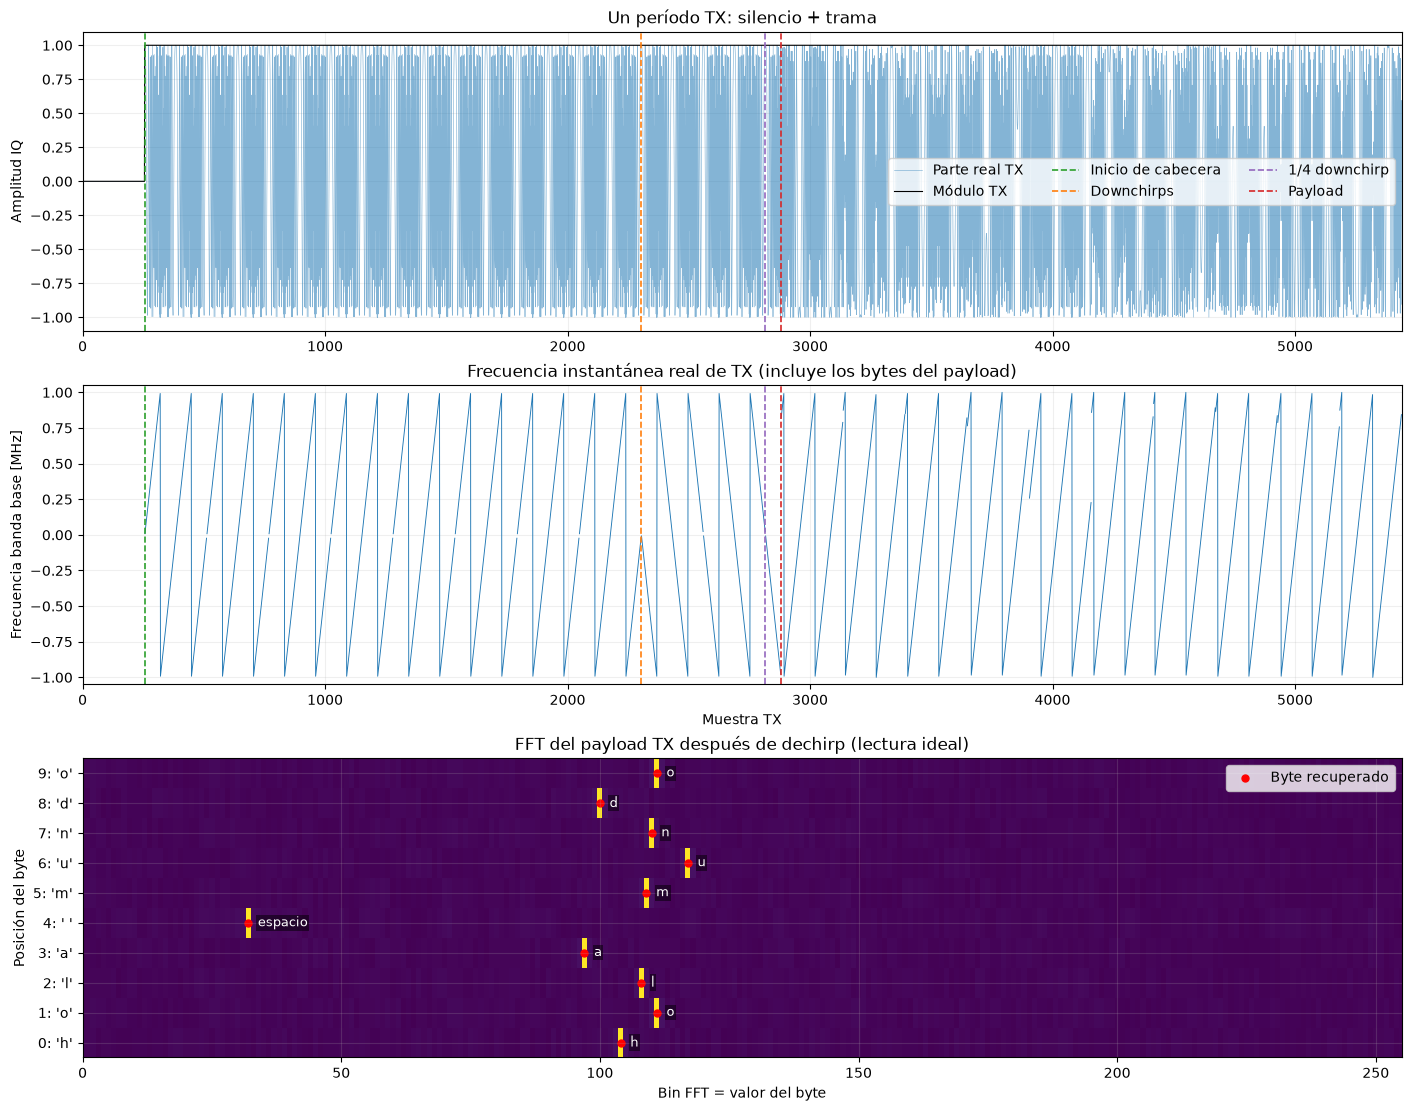

In [8]:
# La frecuencia instantánea se obtiene de la diferencia de fase entre muestras IQ:
# f[n] = Fs/(2π) * arg(x[n] * conj(x[n-1])).
# NO se resta el inicio de cada símbolo: eso ocultaba el desplazamiento del byte.
# Nota: es frecuencia digital en banda base, plegada al intervalo [-Fs/2, Fs/2].
marcas = [(N, 'Inicio de cabecera', 'tab:green'),
          (N + 8*N, 'Downchirps', 'tab:orange'),
          (N + 10*N, '1/4 downchirp', 'tab:purple'),
          (N + len(cabecera), 'Payload', 'tab:red')]

segmentos_tx = ([(N + i*N, N, 'up') for i in range(8)]
                + [(N + 8*N, N, 'down'), (N + 9*N, N, 'down'),
                   (N + 10*N, N//4, 'down')]
                + [(N + len(cabecera) + i*N, N, f'dato {i}')
                   for i in range(len(mensaje))])


def frecuencia_instantanea_tramos(iq, segmentos, fs, amplitud_minima=0.0):
    """Frecuencia de las muestras IQ sin cruzar límites entre símbolos."""
    freq = np.full(len(iq), np.nan, dtype=float)
    for comienzo, largo, _ in segmentos:
        x = iq[comienzo:comienzo+largo]
        if len(x) < 2:
            continue
        producto = x[1:] * np.conj(x[:-1])
        validos = ((np.abs(x[1:]) >= amplitud_minima) &
                   (np.abs(x[:-1]) >= amplitud_minima))
        valores = np.angle(producto) * fs / (2*np.pi)
        freq[comienzo+1:comienzo+largo] = np.where(validos, valores, np.nan)
    return freq

freq_tx = frecuencia_instantanea_tramos(tx_signal, segmentos_tx, FS)

fig, ax = plt.subplots(3, 1, figsize=(14, 11), constrained_layout=True)
ax[0].plot(np.real(tx_signal), lw=0.45, alpha=0.55, label='Parte real TX')
ax[0].plot(np.abs(tx_signal), lw=0.8, color='black', label='Módulo TX')
ax[0].set(title='Un período TX: silencio + trama', ylabel='Amplitud IQ')

ax[1].plot(np.arange(len(tx_signal)), freq_tx / 1e6, lw=0.65, color='tab:blue')
ax[1].set(title='Frecuencia instantánea real de TX (incluye los bytes del payload)',
          xlabel='Muestra TX', ylabel='Frecuencia banda base [MHz]',
          ylim=(-FS/2e6*1.05, FS/2e6*1.05))
for panel in ax[:2]:
    for posicion, nombre, color in marcas:
        panel.axvline(posicion, color=color, ls='--', lw=1.2,
                      label=nombre if panel is ax[0] else None)
    panel.set_xlim(0, len(tx_signal))
ax[0].legend(ncol=3)

ax[2].imshow(20*np.log10(abs(espectros_tx) + 1e-12), aspect='auto', origin='lower')
ax[2].scatter(list(bytes_tx_recuperados), np.arange(len(mensaje)),
              c='red', s=25, label='Byte recuperado')
for fila, byte in enumerate(bytes_tx_recuperados):
    letra = 'espacio' if byte == 32 else chr(byte)
    ax[2].annotate(letra, (byte, fila), xytext=(7, 0), textcoords='offset points',
                   va='center', color='white', fontsize=9,
                   bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', pad=1))
ax[2].set(title='FFT del payload TX después de dechirp (lectura ideal)',
          xlabel='Bin FFT = valor del byte', ylabel='Posición del byte', xlim=(0, N-1))
ax[2].set_yticks(np.arange(len(mensaje)))
ax[2].set_yticklabels([f'{i}: {chr(byte)!r}' for i, byte in enumerate(bytes_tx_recuperados)])
ax[2].legend()
for panel in ax:
    panel.grid(alpha=0.2)
fig.savefig(carpeta_graficos / '01_tx.png', dpi=150)
plt.show()


La trama tiene potencia 1 en sus muestras activas y sus diez bytes se recuperan sin canal. Esa es la referencia para evaluar RX.

## 3. Transmitir, capturar y cerrar el SDR

Esta es la celda de la **primera captura diagnóstica**, que no participa en el cálculo del PER. Más adelante, el barrido experimental vuelve a conectarse al SDR. Usa la configuración de la captura funcional: 2 MS/s, portadora de 915 MHz, ancho de banda de 2 MHz, ganancia TX de −50 dB y AGC RX `slow_attack`. El TX se repite cíclicamente. Se hace **una sola llamada a `rx()`**, con un buffer de 10 880 muestras IQ (dos períodos de la trama), y se copia el resultado a `rx_signal`.

En la versión local de `pyadi-iio`/`libiio` v1, el tamaño del buffer TX cíclico se interpretó en **bytes** aunque `sdr.tx()` recibía muestras IQ de 4 bytes. Al entregar cuatro copias de la trama (21 760 muestras), el bloque efectivo conserva un período completo de 5440 muestras; con una biblioteca corregida, se repiten cuatro períodos idénticos. Así los downchirps y el payload también llegan al TX. El número impreso de muestras entregadas a `sdr.tx()` indica el tamaño del argumento, no verifica por sí solo la señal emitida.

El `finally` atenúa TX, mueve su portadora a 2,4 GHz, destruye ambos buffers y elimina el objeto SDR incluso si falla la adquisición. **No se envía un buffer de ceros**: en la prueba anterior esa operación produjo `Device or resource busy`. Después de esta celda, la detección trabaja con `rx_signal` en memoria; no se guarda un archivo de captura.


In [9]:
rx_signal = None  # Evita analizar una captura anterior si esta ejecución falla.
import adi

sdr = adi.Pluto('ip:192.168.1.34')
try:
    sdr.tx_destroy_buffer()
    sdr.rx_destroy_buffer()
    sdr.loopback = 0
    sdr.sample_rate = FS
    sdr.tx_lo = 915_000_000
    sdr.rx_lo = 915_000_000
    sdr.tx_rf_bandwidth = BW
    sdr.rx_rf_bandwidth = BW
    sdr.tx_hardwaregain_chan0 = -30
    sdr.gain_control_mode_chan0 = 'slow_attack'
    sdr.rx_buffer_size = 2 * len(tx_signal)
    sdr.tx_cyclic_buffer = True

    # Cuatro copias aseguran un período completo con el error de tamaño de bloque de libiio v1.
    tx_para_sdr = np.tile(tx_signal, 4)
    sdr.tx(tx_para_sdr * (2**15 - 1))
    print(f'Envío: {len(tx_para_sdr)} muestras entregadas a sdr.tx; '
          f'período lógico {len(tx_signal)}')

    rx_signal = np.asarray(sdr.rx()).copy()
    print(f'Recepción: {len(rx_signal)} muestras; esperadas {sdr.rx_buffer_size}')
finally:
    try:
        sdr.tx_hardwaregain_chan0 = -89
        sdr.tx_lo = int(2400e6)
    finally:
        try:
            sdr.tx_destroy_buffer()
        finally:
            try:
                sdr.rx_destroy_buffer()
            finally:
                del sdr
                # print('SDR cerrado: buffers liberados y objeto eliminado.')

OSError: [Errno 16] Device or resource busy

## 4. Detectar el inicio y leer el payload

**Inicio temporal.** Deslizamos la cabecera completa sobre la captura. La correlación normalizada al cuadrado vale entre 0 y 1; solo se prueban posiciones donde cabe el payload entero. Se elige el máximo y se acepta si llega a **0,20**.

**Bytes.** Los dos lectores parten de ese mismo inicio. El simple hace dechirp y FFT de cada símbolo; el segundo estima con los ocho upchirps el desvío de frecuencia y lo compensa antes de la misma FFT. Se muestran ambos resultados. Como aquí conocemos `hola mundo`, se prefiere el simple si coincide; si no, el corregido cuando coincide. Esa elección por mensaje conocido es solo para esta prueba: con datos desconocidos haría falta, por ejemplo, un CRC.
**Inicio frecuencial.** En la sección 4.1 también se busca el comienzo de la **misma primera captura** usando la concentración espectral después del dechirping, sin correlacionar con toda la plantilla. Ambos inicios se evalúan con el mismo lector de payload corregido por offset.

$$C[m]=\frac{\left|\sum_{n=0}^{L-1}r[m+n]h^*[n]\right|^2}
{\left(\sum_{n=0}^{L-1}|h[n]|^2\right)\left(\sum_{n=0}^{L-1}|r[m+n]|^2\right)}.$$



In [ ]:
def correlacion_normalizada(iq, referencia):
    largo = len(referencia)
    correlaciones = correlate(iq, referencia, mode='valid', method='fft')
    energia_muestras = np.abs(iq)**2
    energia_referencia = np.sum(np.abs(referencia)**2)
    puntajes = np.zeros(len(correlaciones))

    energia_ventana = np.sum(energia_muestras[:largo])
    for i, correlacion in enumerate(correlaciones):
        if energia_ventana > 0:
            puntajes[i] = np.abs(correlacion)**2 / (energia_ventana * energia_referencia)
        if i + largo < len(iq):
            energia_ventana += energia_muestras[i + largo] - energia_muestras[i]

    return puntajes

def decodificar_simbolos(datos):
    simbolos = datos.reshape(len(mensaje), N)
    sin_chirp = simbolos * np.conj(upchirp)
    espectros = np.abs(np.fft.fft(sin_chirp, axis=1))
    valores = np.argmax(espectros, axis=1)
    return bytes(valores.tolist()), espectros


def leer_payload(iq, inicio):
    comienzo = inicio + len(cabecera)
    datos = iq[comienzo:comienzo + len(payload)]
    return decodificar_simbolos(datos)


def leer_payload_con_offset(iq, inicio):
    # Los 8 primeros chirps son conocidos: al quitarlos queda el giro por offset.
    preambulo = iq[inicio:inicio + 8*N].reshape(8, N)
    sin_chirp = preambulo * np.conj(upchirp)
    pasos_de_fase = sin_chirp[:, 1:] * np.conj(sin_chirp[:, :-1])
    offset_ciclos_por_muestra = np.angle(np.sum(pasos_de_fase)) / (2*np.pi)
    offset_hz = offset_ciclos_por_muestra * FS

    comienzo = inicio + len(cabecera)
    datos = iq[comienzo:comienzo + len(payload)]
    indices = np.arange(len(datos))
    datos_corregidos = datos * np.exp(-2j*np.pi*offset_ciclos_por_muestra*indices)
    mensaje_recibido, espectros = decodificar_simbolos(datos_corregidos)
    return mensaje_recibido, espectros, offset_hz


if rx_signal is None:
    raise RuntimeError('Ejecutá primero la celda SDR; no hay captura válida')

UMBRAL = 0.20
ultimo_inicio = len(rx_signal) - len(trama)
if ultimo_inicio < 0:
    raise RuntimeError('RX no contiene una trama completa')
puntajes = correlacion_normalizada(rx_signal, cabecera)[:ultimo_inicio + 1]
candidato = int(np.argmax(puntajes))
inicio = candidato if puntajes[candidato] >= UMBRAL else None
print(f'Correlación: máximo {puntajes[candidato]:.3f} en muestra {candidato} '
      f'| umbral {UMBRAL:.2f} | inicio aceptado: {inicio}')

bytes_simple = espectros_simple = None
bytes_corregidos = espectros_corregidos = None
bytes_rx = metodo_usado = None
if inicio is not None:
    bytes_simple, espectros_simple = leer_payload(rx_signal, inicio)
    bytes_corregidos, espectros_corregidos, offset_hz = leer_payload_con_offset(rx_signal, inicio)
    print(f'Sin corrección: {bytes_simple!r} | igual a TX: {bytes_simple == mensaje}')
    print(f'Con corrección ({offset_hz:.0f} Hz): {bytes_corregidos!r} '
          f'| igual a TX: {bytes_corregidos == mensaje}')
    if bytes_simple == mensaje:
        metodo_usado, bytes_rx = 'simple', bytes_simple
    elif bytes_corregidos == mensaje:
        metodo_usado, bytes_rx = 'con offset', bytes_corregidos
    print(f'Método elegido: {metodo_usado or "ninguno"} | payload recuperado: {bytes_rx!r}')
else:
    print('Sin lectura de payload: el inicio no superó el umbral.')

Correlación: máximo 0.890 en muestra 3328 | umbral 0.20 | inicio aceptado: 3328
Sin corrección: b'hola mundo' | igual a TX: True
Con corrección (-2669 Hz): b'hola mundo' | igual a TX: True
Método elegido: simple | payload recuperado: b'hola mundo'


## 4.1 Detección en frecuencia en la primera captura

Además de la correlación temporal, usamos **dechirping + FFT** sobre cinco ventanas (dos upchirps, dos downchirps y el primer símbolo del payload). Una ventana bien alineada concentra la potencia en un bin FFT; combinamos las cinco concentraciones con una media geométrica. Se buscan candidatos con un paso grueso y se refinan los mejores. **Ambos detectores reciben exactamente las mismas muestras IQ**; la lectura FFT de bytes también es la misma. La primera captura no participa en el PER.


In [ ]:
# Puntuación del preámbulo de 8 upchirps.
UMBRAL_FRECUENCIA = 0.80


def concentracion_bin_cero(iq):
    puntajes = np.zeros(len(iq) - N + 1)

    for desde in range(0, len(puntajes), 256):
        hasta = min(desde + 256, len(puntajes))
        ventanas = np.array([iq[i:i + N] for i in range(desde, hasta)])
        espectros = np.abs(np.fft.fft(ventanas * np.conj(upchirp), axis=1))**2
        energia = np.sum(espectros, axis=1)
        energia[energia == 0] = 1  # Una ventana vacía obtiene puntaje 0.
        puntajes[desde:hasta] = espectros[:, 0] / energia

    return puntajes

def detectar_temporal(iq):
    ultimo_inicio = len(iq) - len(trama)
    if ultimo_inicio < 0:
        return None, 0.0
    scores = correlacion_normalizada(iq, cabecera)[:ultimo_inicio + 1]
    idx = int(np.argmax(scores))
    score = float(scores[idx])
    return (idx if score >= UMBRAL else None), score


def detectar_frecuencia(iq):
    ultimo_inicio = len(iq) - len(trama)
    if ultimo_inicio < 0:
        return None, 0.0

    concentraciones = concentracion_bin_cero(iq)
    puntajes = np.zeros(ultimo_inicio + 1)
    for inicio in range(ultimo_inicio + 1):
        puntajes[inicio] = min(concentraciones[inicio + j*N] for j in range(8))

    mejor = int(np.argmax(puntajes))
    puntaje = float(puntajes[mejor])
    return (mejor if puntaje >= UMBRAL_FRECUENCIA else None), puntaje

def paquete_correcto(iq, detector):
    inicio_rx, calidad = detector(iq)
    if inicio_rx is None:
        return False, None, calidad, None
    try:
        bytes_rx, _, _ = leer_payload_con_offset(iq, inicio_rx)
    except (ValueError, IndexError):
        return False, inicio_rx, calidad, None
    return bytes_rx == mensaje, inicio_rx, calidad, bytes_rx


def describir_primera_captura(iq):
    print('--- Comparación de detectores sobre la PRIMERA captura (no PER) ---')
    for nombre, detector in [('Temporal', detectar_temporal),
                             ('Frecuencia', detectar_frecuencia)]:
        correcto, pos, score, bytes_rx = paquete_correcto(iq, detector)
        print(f'{nombre:10s} | inicio={str(pos):>6s} | score={score:.4f} '
              f'| datos={bytes_rx!r} | correcto={correcto}')


# Guardamos ambos inicios para las gráficas siguientes.
inicio_frecuencia, puntaje_frecuencia = detectar_frecuencia(rx_signal)
inicio_temporal, puntaje_temporal = detectar_temporal(rx_signal)

describir_primera_captura(rx_signal)

--- Comparación de detectores sobre la PRIMERA captura (no PER) ---
Temporal   | inicio=  3328 | score=0.8900 | datos=b'hola mundo' | correcto=True
Frecuencia | inicio=  3328 | score=0.8901 | datos=b'hola mundo' | correcto=True


## 5. Ver y entender la captura

**Figura 1.** Arriba, toda la señal recibida; abajo, la curva de **correlación temporal** (la detección en frecuencia se calcula por separado en la sección 4.1). La línea roja es el umbral 0,20. Los puntos naranjas son otros picos sobre el umbral y el violeta es el máximo elegido; esos puntos adicionales no cambian la decisión. Esta figura y las siguientes se guardan como PNG en `graficos_vpn/`, junto con la figura del TX de la sección 2. La carpeta se crea en el directorio desde el que se ejecuta el notebook.


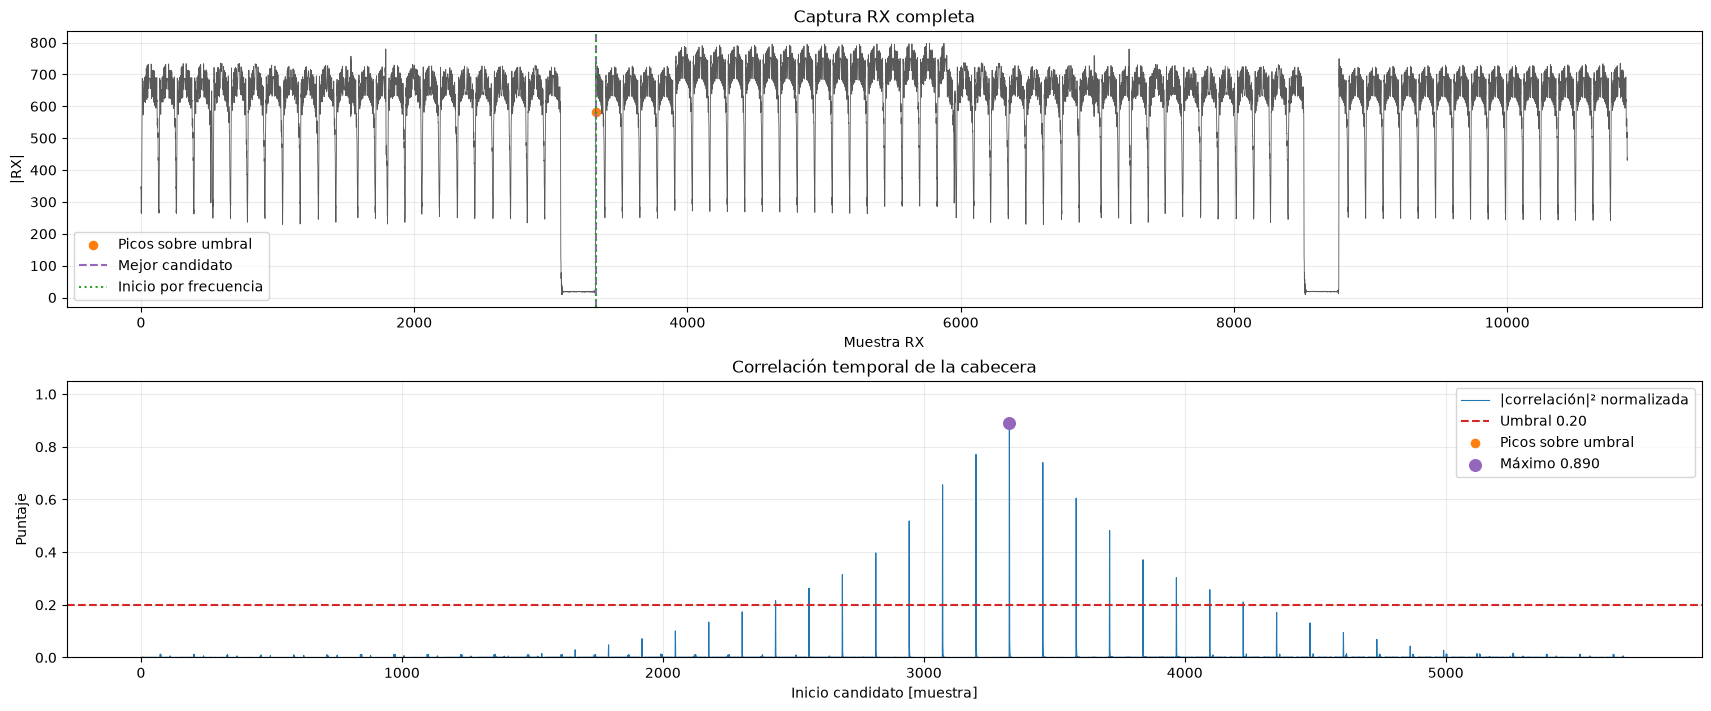

Picos sobre umbral: [3328]


In [ ]:
envolvente = np.abs(rx_signal)
picos, _ = find_peaks(puntajes, height=UMBRAL, distance=len(cabecera))
fig, ax = plt.subplots(2, 1, figsize=(17, 7), constrained_layout=True)
x = np.arange(len(rx_signal))
ax[0].plot(x, envolvente, color='0.35', lw=0.6)
ax[0].scatter(picos, envolvente[picos], color='tab:orange', s=35,
              label='Picos sobre umbral')
ax[0].axvline(candidato, color='tab:purple', ls='--', label='Mejor candidato')
if inicio_frecuencia is not None:
    ax[0].axvline(inicio_frecuencia, color='tab:green', ls=':', lw=1.5,
                  label='Inicio por frecuencia')
ax[0].set(title='Captura RX completa', xlabel='Muestra RX', ylabel='|RX|')
ax[0].legend()

ax[1].plot(puntajes, color='tab:blue', lw=0.8, label='|correlación|² normalizada')
ax[1].axhline(UMBRAL, color='tab:red', ls='--', label=f'Umbral {UMBRAL:.2f}')
ax[1].scatter(picos, puntajes[picos], color='tab:orange', s=35,
              label='Picos sobre umbral')
ax[1].scatter(candidato, puntajes[candidato], color='tab:purple', s=70,
              zorder=3, label=f'Máximo {puntajes[candidato]:.3f}')
ax[1].set(xlabel='Inicio candidato [muestra]', ylabel='Puntaje',
          title='Correlación temporal de la cabecera', ylim=(0, 1.05))
ax[1].legend()
for panel in ax:
    panel.grid(alpha=0.25)
fig.savefig(carpeta_graficos / "02_rx_y_correlacion.png", dpi=150)
plt.show()
print('Picos sobre umbral:', picos.tolist())

**Figura 2.** El zoom sitúa el candidato y los límites esperados de la cabecera. Las barras comparan cada parte con su plantilla para diagnosticar un fallo; **no** son otro criterio de detección.

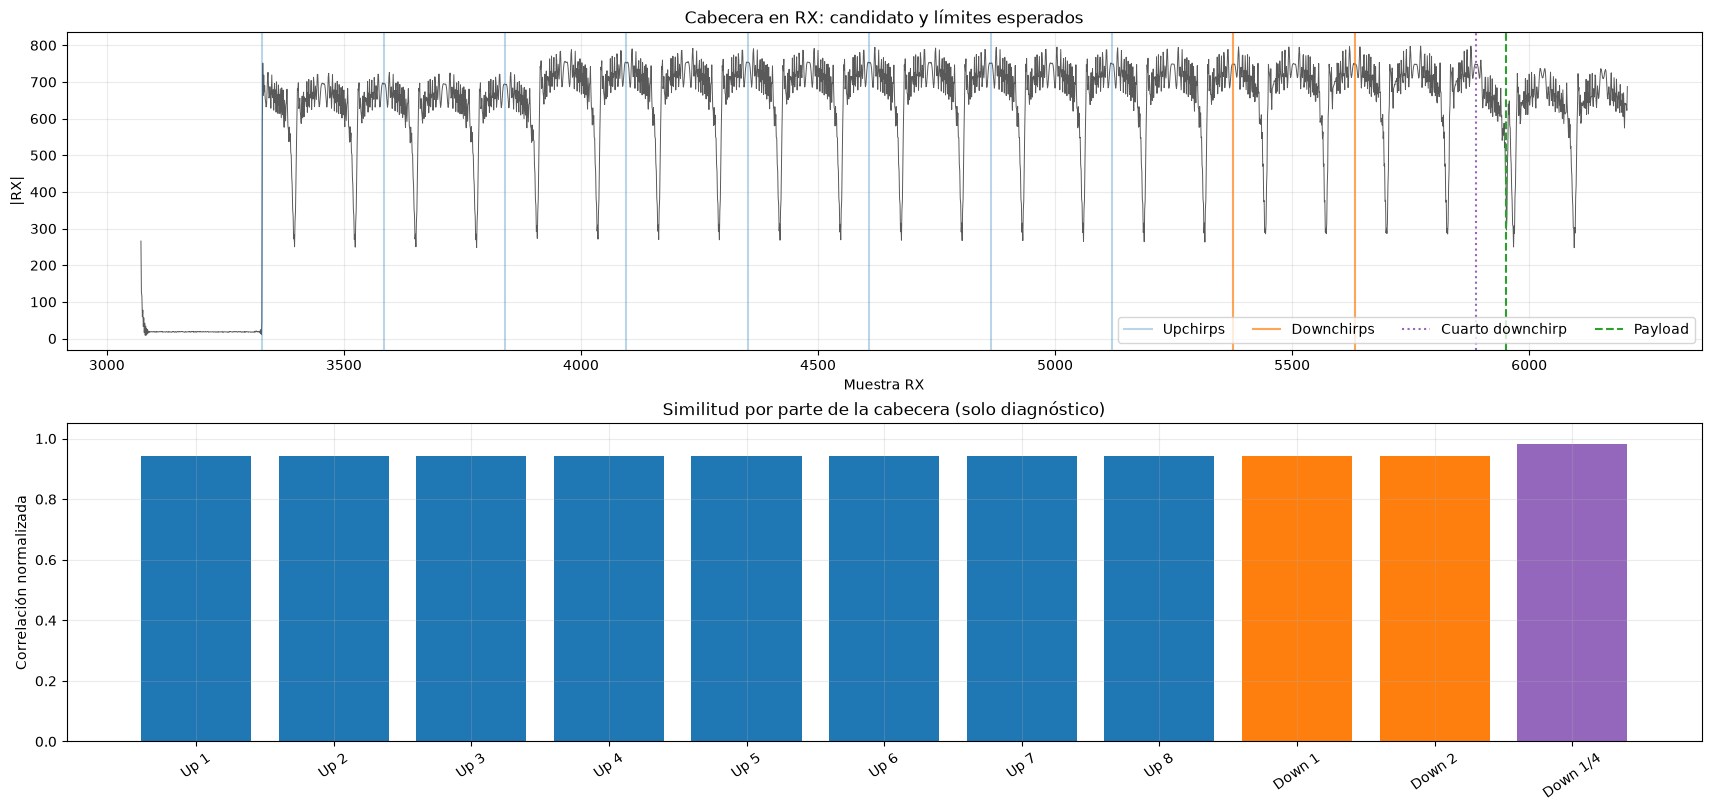

In [ ]:
a = max(0, candidato - N)
b = min(len(rx_signal), candidato + len(cabecera) + N)
fig, ax = plt.subplots(2, 1, figsize=(17, 8), constrained_layout=True)
ax[0].plot(np.arange(a, b), envolvente[a:b], color='0.35', lw=0.7)
for j in range(8):
    ax[0].axvline(candidato+j*N, color='tab:blue', alpha=0.3,
                  label='Upchirps' if j == 0 else None)
for j in range(2):
    ax[0].axvline(candidato+(8+j)*N, color='tab:orange', alpha=0.7,
                  label='Downchirps' if j == 0 else None)
ax[0].axvline(candidato+10*N, color='tab:purple', ls=':',
              label='Cuarto downchirp')
ax[0].axvline(candidato+len(cabecera), color='tab:green', ls='--',
              label='Payload')
ax[0].set(title='Cabecera en RX: candidato y límites esperados',
          xlabel='Muestra RX', ylabel='|RX|')
ax[0].legend(ncol=4)

segmentos = [(f'Up {j+1}', j*N, (j+1)*N) for j in range(8)]
segmentos += [('Down 1', 8*N, 9*N), ('Down 2', 9*N, 10*N),
             ('Down 1/4', 10*N, len(cabecera))]
calidad = []
for _, desde, hasta in segmentos:
    ref = cabecera[desde:hasta]
    recibido = rx_signal[candidato+desde:candidato+hasta]
    denominador = np.linalg.norm(ref) * np.linalg.norm(recibido)
    calidad.append(float(np.abs(np.vdot(ref, recibido)) / denominador)
                   if denominador else 0.0)
ax[1].bar(np.arange(len(segmentos)), calidad, color=['tab:blue']*8 +
          ['tab:orange']*2 + ['tab:purple'])
ax[1].set_xticks(np.arange(len(segmentos)),
                 [nombre for nombre, _, _ in segmentos], rotation=35)
ax[1].set(title='Similitud por parte de la cabecera (solo diagnóstico)',
          ylabel='Correlación normalizada', ylim=(0, 1.05))
for panel in ax:
    panel.grid(alpha=0.25)
fig.savefig(carpeta_graficos / "03_cabecera.png", dpi=150)
plt.show()

**Figura 3.** Los dos lectores procesan la **misma captura y el mismo inicio**. Cada fila muestra la FFT de un byte: rojo es el byte leído y el círculo blanco es el enviado. Así se ve dónde ayuda la corrección de frecuencia.

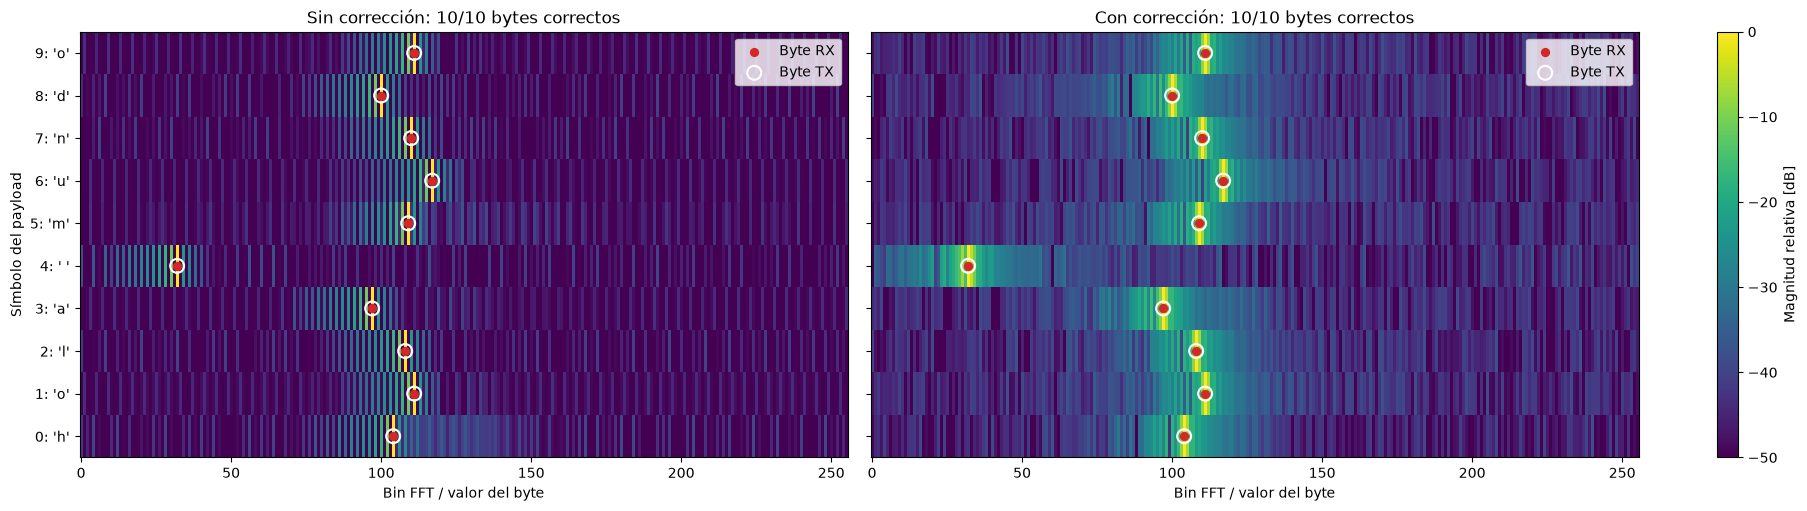

Método elegido para esta captura: simple


In [ ]:
if inicio is None:
    print('No hay espectros de bytes: el inicio no superó el umbral.')
else:
    fig, ax = plt.subplots(1, 2, figsize=(18, 5), sharey=True,
                           constrained_layout=True)
    filas = np.arange(len(mensaje))
    for panel, nombre, leidos, espectros in [
        (ax[0], 'Sin corrección', bytes_simple, espectros_simple),
        (ax[1], 'Con corrección', bytes_corregidos, espectros_corregidos),
    ]:
        espectros_db = 20*np.log10(
            espectros / np.maximum(espectros.max(axis=1, keepdims=True), 1e-12)
            + 1e-12)
        im = panel.imshow(espectros_db, aspect='auto', origin='lower',
                          extent=(-0.5, N-0.5, -0.5, len(mensaje)-0.5),
                          vmin=-50, vmax=0, cmap='viridis')
        panel.scatter(np.frombuffer(leidos, dtype=np.uint8), filas,
                      color='tab:red', s=32, label='Byte RX')
        panel.scatter(np.frombuffer(mensaje, dtype=np.uint8), filas,
                      facecolors='none', edgecolors='white', s=100,
                      linewidths=1.5, label='Byte TX')
        aciertos = sum(a == b for a, b in zip(leidos, mensaje))
        panel.set(title=f'{nombre}: {aciertos}/{len(mensaje)} bytes correctos',
                  xlabel='Bin FFT / valor del byte')
        panel.set_yticks(filas, [f'{i}: {chr(b)!r}' for i, b in enumerate(mensaje)])
        panel.legend()
    ax[0].set_ylabel('Símbolo del payload')
    fig.colorbar(im, ax=ax, label='Magnitud relativa [dB]')
    fig.savefig(carpeta_graficos / "04_bytes.png", dpi=150)
    plt.show()
    print('Método elegido para esta captura:', metodo_usado or 'ninguno')

## 5.1 Frecuencia instantánea de la señal recibida

Se grafica la frecuencia **en banda base**, estimada con la diferencia de fase entre muestras IQ contiguas, sin conectar muestras de símbolos distintos. Se muestra una trama desde el inicio temporal (o desde el inicio frecuencial, si el temporal no aparece); se descartan pares con amplitud muy baja porque su fase es poco confiable. En RX es normal ver más ruido y desplazamientos de frecuencia que en TX. Los saltos de +Fs/2 a −Fs/2 son el plegado digital de la frecuencia.


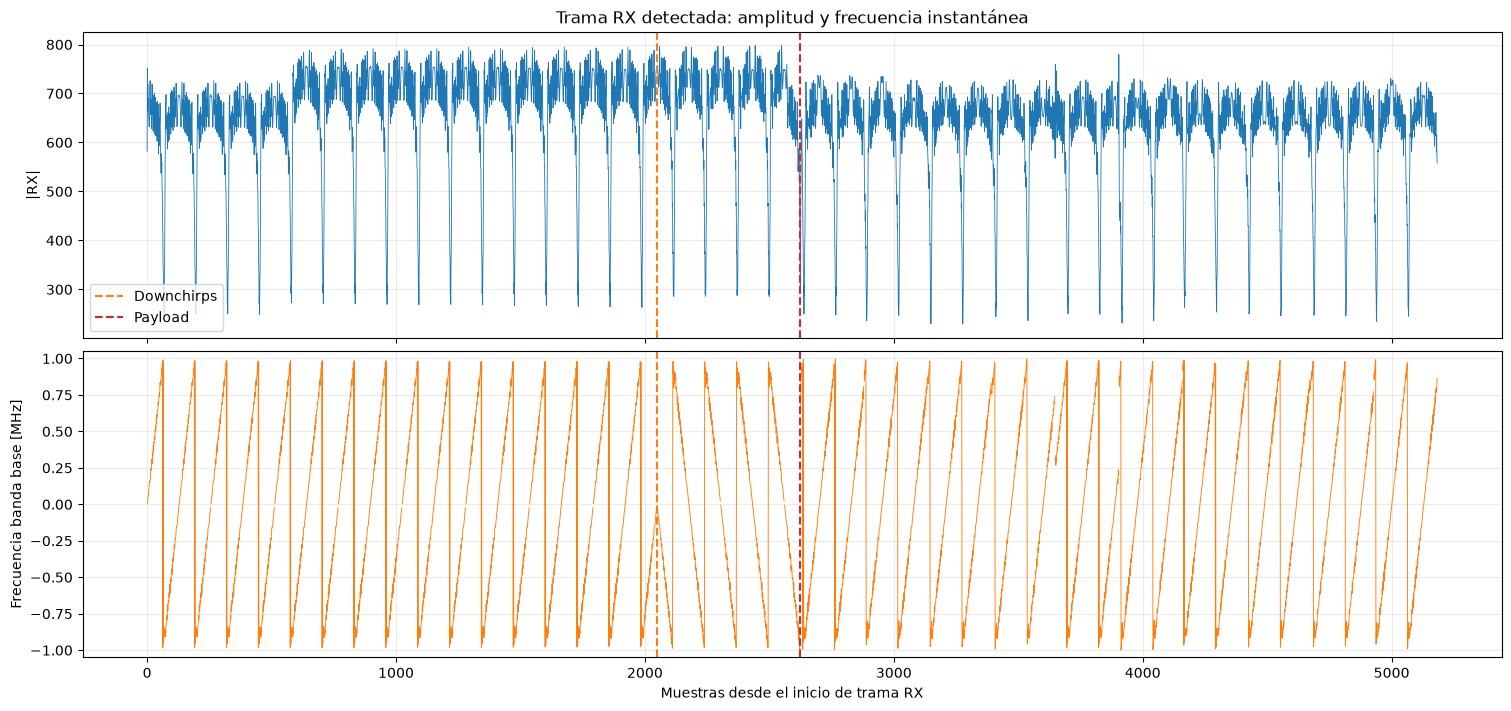

Inicio para gráfico RX: 3328; umbral de amplitud: 53.43


In [ ]:
# Zoom de una trama RX, desde el inicio hallado por uno de los detectores.
inicio_rx_graf = inicio if inicio is not None else detectar_frecuencia(rx_signal)[0]
if inicio_rx_graf is None:
    print('No se detectó una trama completa: no se grafica su frecuencia instantánea.')
else:
    segmentos_rx = [(inicio_rx_graf + desplazamiento, largo, tipo)
                    for desplazamiento, largo, tipo in
                    [(s-N, largo, tipo) for s, largo, tipo in segmentos_tx]]
    # Se excluyen muestras con amplitud muy pequeña (fase dominada por ruido).
    tramo_rx = rx_signal[inicio_rx_graf:inicio_rx_graf+len(trama)]
    umbral_amplitud = 0.08 * np.median(np.abs(tramo_rx))
    freq_rx = frecuencia_instantanea_tramos(
        rx_signal, segmentos_rx, FS, amplitud_minima=umbral_amplitud)
    a_rx, b_rx = inicio_rx_graf, inicio_rx_graf + len(trama)
    x_rx = np.arange(a_rx, b_rx) - inicio_rx_graf
    fig, axs = plt.subplots(2, 1, figsize=(15, 7), constrained_layout=True, sharex=True)
    axs[0].plot(x_rx, np.abs(rx_signal[a_rx:b_rx]), lw=0.6)
    axs[0].set(ylabel='|RX|', title='Trama RX detectada: amplitud y frecuencia instantánea')
    axs[1].plot(x_rx, freq_rx[a_rx:b_rx]/1e6, lw=0.65, color='tab:orange')
    axs[1].set(xlabel='Muestras desde el inicio de trama RX',
               ylabel='Frecuencia banda base [MHz]',
               ylim=(-FS/2e6*1.05, FS/2e6*1.05))
    for axx in axs:
        axx.axvline(8*N, ls='--', c='tab:orange', label='Downchirps')
        axx.axvline(len(cabecera), ls='--', c='tab:red', label='Payload')
        axx.grid(alpha=0.25)
    axs[0].legend()
    fig.savefig(carpeta_graficos / '05_frecuencia_instantanea_rx.png', dpi=150)
    plt.show()
    print(f'Inicio para gráfico RX: {inicio_rx_graf}; umbral de amplitud: {umbral_amplitud:.2f}')


## 6. Comparación PER vs atenuación (Pluto SDR)

Se transmite **el mismo paquete** en cada ensayo y cada nueva captura se analiza por separado con el detector temporal y el frecuencial. El primer paquete mostrado arriba es independiente y **no se cuenta** en este barrido. Partimos de **25 dB adicionales** y usamos un gráfico semilogarítmico (log en PER). La referencia TX de este barrido es −60 dB, distinta de la primera captura diagnóstica de −30 dB, para permitir alcanzar 30 dB adicionales sin superar el límite de ganancia del Pluto (−89 dB).

**Nota:** el SDR transmite el buffer cíclicamente y cada llamada a RX es un ensayo de captura; aunque entren varias copias del paquete en una captura, esta cuenta una sola vez.


In [237]:
# Barrido: referencia -60 dB; 5, 10, 15, 20 dB adicionales.
GANANCIA_TX_REFERENCIA_DB = -60
ATENUACIONES_DB = np.arange(0, 21, 5)
TRANSMISIONES_POR_ATENUACION = 1000
GANANCIA_RX_FIJA_DB = 30
DIRECCION_PLUTO = 'ip:192.168.1.34'

In [ ]:
# Nueva conexión: se adquieren 100 capturas por cada atenuación.
# Cada par (temporal, frecuencia) corresponde a EXACTAMENTE la misma captura IQ.
import adi
runSDR = False
if runSDR == True:

    resultados = []
    sdr = adi.Pluto(DIRECCION_PLUTO)
    try:
        sdr.tx_destroy_buffer()
        sdr.rx_destroy_buffer()
        sdr.loopback = 0
        sdr.sample_rate = FS
        sdr.tx_lo = 915_000_000
        sdr.rx_lo = 915_000_000
        sdr.tx_rf_bandwidth = BW
        sdr.rx_rf_bandwidth = BW
        sdr.gain_control_mode_chan0 = 'manual'
        sdr.rx_hardwaregain_chan0 = GANANCIA_RX_FIJA_DB
        sdr.rx_buffer_size = 2 * len(tx_signal)
        sdr.tx_cyclic_buffer = True
        sdr.tx(np.tile(tx_signal, 4) * (2**15 - 1))

        for atenuacion in ATENUACIONES_DB:
            sdr.tx_hardwaregain_chan0 = float(GANANCIA_TX_REFERENCIA_DB - atenuacion)
            errores_t = errores_f = 0
            for ensayo in range(TRANSMISIONES_POR_ATENUACION):
                rx = np.asarray(sdr.rx()).copy()
                correcto_t, _, _, _ = paquete_correcto(rx, detectar_temporal)
                correcto_f, _, _, _ = paquete_correcto(rx, detectar_frecuencia)
                errores_t += int(not correcto_t)
                errores_f += int(not correcto_f)
            per_t = errores_t / TRANSMISIONES_POR_ATENUACION
            per_f = errores_f / TRANSMISIONES_POR_ATENUACION
            resultados.append((float(atenuacion), per_t, per_f, errores_t, errores_f))
            print(f'Att extra {atenuacion:4.0f} dB | TX={sdr.tx_hardwaregain_chan0:6.1f} dB '
                f'| PER temporal={per_t:.4f} ({errores_t}/{TRANSMISIONES_POR_ATENUACION}) '
                f'| PER frecuencia={per_f:.4f} ({errores_f}/{TRANSMISIONES_POR_ATENUACION})')
    finally:
        try:
            sdr.tx_hardwaregain_chan0 = -89
            sdr.tx_lo = int(2400e6)
        finally:
            try:
                sdr.tx_destroy_buffer()
            finally:
                try:
                    sdr.rx_destroy_buffer()
                finally:
                    del sdr


Att extra    0 dB | TX= -60.0 dB | PER temporal=0.0000 (0/1000) | PER frecuencia=0.0000 (0/1000)
Att extra    5 dB | TX= -65.0 dB | PER temporal=0.0000 (0/1000) | PER frecuencia=0.0000 (0/1000)
Att extra   10 dB | TX= -70.0 dB | PER temporal=0.0090 (9/1000) | PER frecuencia=0.0230 (23/1000)
Att extra   15 dB | TX= -75.0 dB | PER temporal=0.2460 (246/1000) | PER frecuencia=0.9940 (994/1000)
Att extra   20 dB | TX= -80.0 dB | PER temporal=0.4860 (486/1000) | PER frecuencia=1.0000 (1000/1000)


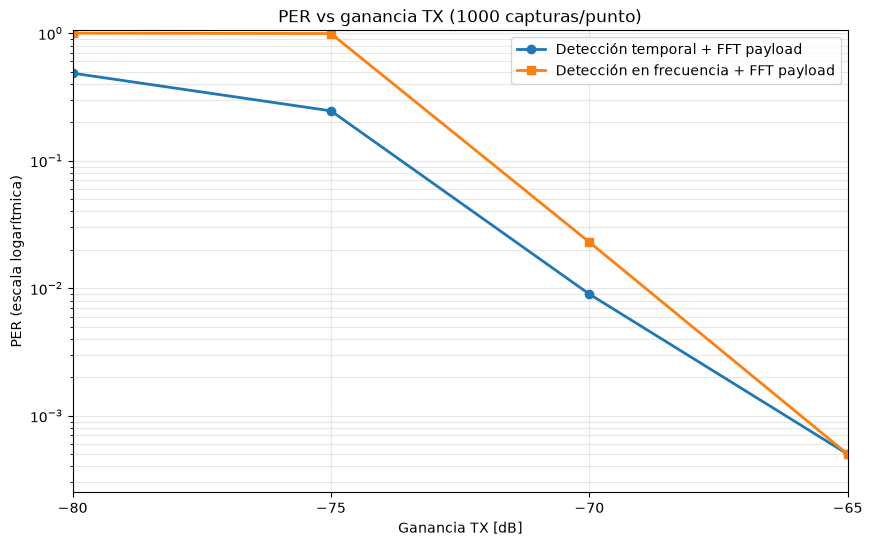

In [239]:
# PER vs ganancia TX
if not resultados:
    raise RuntimeError('Primero ejecutá el barrido de atenuación.')

datos = np.array(resultados, dtype=float)

# Convertir atenuación adicional en ganancia TX
ganancias_tx = GANANCIA_TX_REFERENCIA_DB - datos[:, 0]

# Evitar valores 0 en escala logarítmica
piso_plot = 0.5 / TRANSMISIONES_POR_ATENUACION
per_temporal_plot = np.maximum(datos[:, 1], piso_plot)
per_frecuencia_plot = np.maximum(datos[:, 2], piso_plot)

fig, ax = plt.subplots(figsize=(10, 6))

ax.semilogy(ganancias_tx, per_temporal_plot, 'o-', lw=2,
            label='Detección temporal + FFT payload')

ax.semilogy(ganancias_tx, per_frecuencia_plot, 's-', lw=2,
            label='Detección en frecuencia + FFT payload')

ax.set(
    xlabel='Ganancia TX [dB]',
    ylabel='PER (escala logarítmica)',
    title=f'PER vs ganancia TX ({TRANSMISIONES_POR_ATENUACION} capturas/punto)'
)

ax.set_xlim(-80, -65)
ax.set_xticks(np.arange(-80, -64, 5))
ax.set_ylim(piso_plot / 2, 1.05)

ax.grid(True, which='both', alpha=0.3)
ax.legend()

plt.show()

## 7. Conclusión

La primera captura se analiza con dos detectores de inicio independientes: correlación temporal y concentración espectral por FFT de chirps. También se grafican las frecuencias instantáneas del TX y de la trama RX. Finalmente, el barrido a partir de 25 dB adicionales compara el PER de ambos detectores **en las mismas capturas** y presenta las dos curvas con escala logarítmica en el eje PER. Una coincidencia con los bytes conocidos valida este experimento didáctico, pero para payloads desconocidos haría falta CRC. Los resultados medidos requieren conectar el Pluto SDR.
